# Chapter 5: Classification

This notebook reproduces the Python code from Chapter 5 of *Practical Statistics for Data Scientists* (2nd Edition) by Peter Bruce, Andrew Bruce, and Peter Gedeck.

Classification is the task of predicting which category a record belongs to, such as whether a loan will default or be paid off. The chapter covers naive Bayes, discriminant analysis, and logistic regression, then discusses how to evaluate classification models (confusion matrix, precision, recall, ROC, AUC) and strategies for dealing with imbalanced data. It ends by comparing the decision boundaries of different classifiers.

In [35]:
from pathlib import Path

import pandas as pd
import numpy as np

from sklearn.naive_bayes import MultinomialNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support,
                             roc_curve, roc_auc_score)

import statsmodels.api as sm
import statsmodels.formula.api as smf

from imblearn.over_sampling import SMOTE, ADASYN
from pygam import LinearGAM, s
from dmba import classificationSummary

import seaborn as sns
import matplotlib.pyplot as plt

DATA = Path('data')
LOAN3000_CSV = DATA / 'loan3000.csv'
LOAN_DATA_CSV = DATA / 'loan_data.csv.gz'
FULL_TRAIN_SET_CSV = DATA / 'full_train_set.csv.gz'

## 1. Naive Bayes

The **naive Bayes** algorithm uses the probability of observing predictor values, given an outcome, to estimate the probability of the outcome given the predictor values.

The exact Bayesian approach would only use records that match the new record on **all** predictors, which quickly becomes impossible because most combinations are rare. Naive Bayes solves this by assuming that the predictors are **conditionally independent** given the outcome:
1. For each class, estimate the conditional probability of each predictor value (e.g., P(purpose = credit card | default)).
2. Multiply these probabilities together, along with the overall proportion of that class.
3. Divide by the sum across all classes to get the probability of each class for the new record.

Even though the independence assumption is rarely true, naive Bayes often ranks records reasonably well, although its probability estimates are usually biased.

Naive Bayes works with **categorical predictors**. The example predicts whether a loan will default using loan purpose, home ownership, and employment length.

In [36]:
loan_data = pd.read_csv(LOAN_DATA_CSV)

# convert to categorical
loan_data['outcome'] = loan_data['outcome'].astype('category')
loan_data['purpose_'] = loan_data['purpose_'].astype('category')
loan_data['home_'] = loan_data['home_'].astype('category')
loan_data['emp_len_'] = loan_data['emp_len_'].astype('category')

predictors = ['purpose_', 'home_', 'emp_len_']
outcome = 'outcome'
X = pd.get_dummies(loan_data[predictors], prefix='', prefix_sep='', dtype=int)
y = loan_data[outcome]

naive_model = MultinomialNB(alpha=1e-10, fit_prior=False)
naive_model.fit(X, y)

new_loan = X.loc[146:146, :]
print('predicted class:', naive_model.predict(new_loan)[0])

probabilities = pd.DataFrame(naive_model.predict_proba(new_loan),
                             columns=naive_model.classes_)
print('predicted probabilities')
print(probabilities)

predicted class: default
predicted probabilities
    default  paid off
0  0.653699  0.346301


For loan number 146, the model predicts `default`, based only on its purpose, home ownership status, and employment length. A very small `alpha` means almost no smoothing is applied, and `fit_prior=False` means both classes are given equal prior probability.

### Numeric Predictor Variables

The scikit-learn multinomial naive Bayes model only works with categorical (count-like) predictors. To use numeric predictors, they must either be **binned** into categories, or modeled with a probability distribution such as the normal distribution (as in Gaussian naive Bayes). This example is shown in R in the book and is not reproduced in Python.

## 2. Discriminant Analysis

**Discriminant analysis** is one of the earliest statistical classifiers, introduced by R. A. Fisher in 1936. The most common form is **linear discriminant analysis (LDA)**.

Key ideas:
- **Covariance**: a measure of how much one variable varies together with another.
- **Discriminant function**: a function that, applied to the predictors, maximizes the separation between the classes.
- **Discriminant weights**: the coefficients of the discriminant function.

LDA finds a linear combination of the predictors that maximizes the ratio of the variability **between** classes to the variability **within** classes. It assumes the predictors are normally distributed with the same covariance matrix in each class, although it often works well even when these assumptions are not exactly met.

### 2.1 A Simple Example

The example uses two predictors: the borrower's credit score (`borrower_score`) and the ratio of loan payment to income (`payment_inc_ratio`).

In [37]:
loan3000 = pd.read_csv(LOAN3000_CSV)
loan3000['outcome'] = loan3000['outcome'].astype('category')

predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_lda = LinearDiscriminantAnalysis()
loan_lda.fit(X, y)
print(pd.DataFrame(loan_lda.scalings_, index=X.columns))

                          0
borrower_score     7.178232
payment_inc_ratio -0.099709


The discriminant weights show that `borrower_score` has a large positive weight, while `payment_inc_ratio` has a small negative weight. A higher credit score pushes a loan toward being paid off, while a higher payment-to-income ratio pushes it toward default.

In [38]:
pred = pd.DataFrame(loan_lda.predict_proba(loan3000[predictors]),
                    columns=loan_lda.classes_)
print(pred.head())

    default  paid off
0  0.553591  0.446409
1  0.559004  0.440996
2  0.272576  0.727424
3  0.506270  0.493730
4  0.610035  0.389965


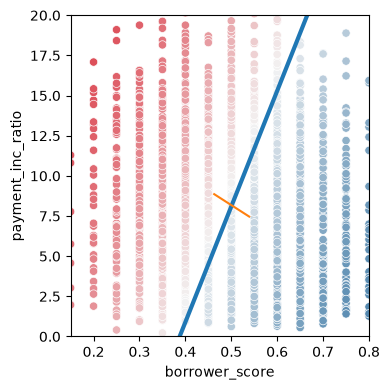

In [39]:
# Use scalings and center of means to determine decision boundary
center = np.mean(loan_lda.means_, axis=0)
slope = -loan_lda.scalings_[0] / loan_lda.scalings_[1]
intercept = center[1] - center[0] * slope

# payment_inc_ratio for borrower_score of 0 and 20
x_0 = (0 - intercept) / slope
x_20 = (20 - intercept) / slope

lda_df = pd.concat([loan3000, pred['default']], axis=1)

fig, ax = plt.subplots(figsize=(4, 4))
sns.scatterplot(x='borrower_score', y='payment_inc_ratio',
                hue='default', data=lda_df,
                palette=sns.diverging_palette(240, 10, n=9, as_cmap=True),
                ax=ax, legend=False)

ax.set_ylim(0, 20)
ax.set_xlim(0.15, 0.8)
ax.plot((x_0[0], x_20[0]), (0, 20), linewidth=3)
ax.plot(*loan_lda.means_.transpose())

plt.tight_layout()
plt.show()

Each point is colored by its predicted probability of default. The thick line is the LDA decision boundary: loans on one side are classified as default, and on the other side as paid off. Points further from the line are classified with more confidence. Borrowers with a lower credit score and a higher payment-to-income ratio tend to fall on the default side.

## 3. Logistic Regression

**Logistic regression** is similar to linear regression, but the outcome is binary. It is popular because it is fast to compute and produces a model that is easy to interpret.

### 3.1 Logistic Response Function and Logit

Key terms:
- **Logit**: the function that maps a probability (0 to 1) onto the range -∞ to +∞. Also called log odds.
- **Odds**: the ratio of "success" to "not success": p / (1 - p).
- **Log odds**: the response in the transformed model, which is linear in the predictors.

The model works in three steps:
1. Model the log odds as a linear function of the predictors: log(p / (1 - p)) = b0 + b1·X1 + ... + bq·Xq.
2. Convert the log odds back to a probability using the **logistic function**: p = 1 / (1 + e^-(b0 + b1·X1 + ...)).
3. Apply a cutoff (commonly 0.5) to the probability to classify each record.

The plot below shows the relationship between probability and the logit.

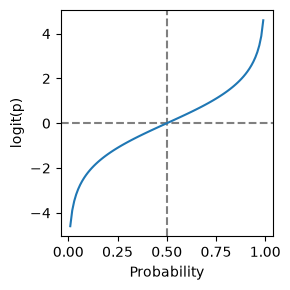

In [40]:
p = np.arange(0.01, 1, 0.01)
df = pd.DataFrame({
    'p': p,
    'logit': np.log(p / (1 - p)),
    'odds': p / (1 - p),
})

fig, ax = plt.subplots(figsize=(3, 3))
ax.axhline(0, color='grey', linestyle='--')
ax.axvline(0.5, color='grey', linestyle='--')
ax.plot(df['p'], df['logit'])
ax.set_xlabel('Probability')
ax.set_ylabel('logit(p)')

plt.tight_layout()
plt.show()

A probability of 0.5 corresponds to a logit of 0. As the probability approaches 0 or 1, the logit goes toward negative or positive infinity.

### 3.2 Logistic Regression and the GLM

The package scikit-learn has a specialized class for `LogisticRegression`, while statsmodels has a more general method based on the generalized linear model (GLM). A very large value of `C` effectively removes regularization, so the model behaves like a standard (unpenalized) logistic regression.

In [41]:
predictors = ['payment_inc_ratio', 'purpose_', 'home_', 'emp_len_',
              'borrower_score']
outcome = 'outcome'
X = pd.get_dummies(loan_data[predictors], prefix='', prefix_sep='',
                   drop_first=True, dtype=int)
y = loan_data[outcome]

logit_reg = LogisticRegression(C=1e42, solver='liblinear')
logit_reg.fit(X, y)

print('intercept', logit_reg.intercept_[0])
print('classes', logit_reg.classes_)
pd.DataFrame({'coeff': logit_reg.coef_[0]}, index=X.columns)

intercept -1.638088683407208
classes ['default' 'paid off']


,coeff
payment_inc_ratio,-0.079728
borrower_score,4.611037
debt_consolidation,-0.249342
home_improvement,-0.407614
major_purchase,-0.229376
medical,-0.510087
other,-0.620534
small_business,-1.215662
OWN,-0.048453
RENT,-0.157355


scikit-learn orders the classes alphabetically (`default`, then `paid off`), and the coefficients describe the log odds of the **second** class, `paid off`. So a positive coefficient (like `borrower_score`) increases the chance of a loan being paid off, while a negative coefficient (like `small_business`) increases the chance of default. Because of this ordering, the signs are reversed compared to the R model in the book.

The reference categories, which are dropped when creating dummy variables, can be checked below.

In [42]:
print(loan_data['purpose_'].cat.categories)
print(loan_data['home_'].cat.categories)
print(loan_data['emp_len_'].cat.categories)

Index(['credit_card', 'debt_consolidation', 'home_improvement',
       'major_purchase', 'medical', 'other', 'small_business'],
      dtype='str')
Index(['MORTGAGE', 'OWN', 'RENT'], dtype='str')
Index([' < 1 Year', ' > 1 Year'], dtype='str')


The first category of each variable (`credit_card`, `MORTGAGE`, ` < 1 Year`) is the reference level, so the other coefficients are interpreted relative to it.

If the outcome should be modeled the other way around, `OrdinalEncoder` can be used to explicitly encode `paid off` as 0 and `default` as 1. This reverses the order of the classes, so the coefficients now describe the log odds of default and have the opposite sign.

In [43]:
enc = OrdinalEncoder(categories=[['paid off', 'default']])
y_enc = enc.fit_transform(loan_data[[outcome]]).ravel()

logit_reg_enc = LogisticRegression(C=1e42, solver='liblinear')
logit_reg_enc.fit(X, y_enc)

print('intercept', logit_reg_enc.intercept_[0])
print('classes', logit_reg_enc.classes_)
pd.DataFrame({'coeff': logit_reg_enc.coef_[0]}, index=X.columns)

intercept 1.6380885435754573
classes [0. 1.]


,coeff
payment_inc_ratio,0.079728
borrower_score,-4.611037
debt_consolidation,0.249342
home_improvement,0.407614
major_purchase,0.229376
medical,0.510087
other,0.620534
small_business,1.215662
OWN,0.048453
RENT,0.157355


### 3.3 Predicted Values from Logistic Regression

The model can return predictions as log odds or as probabilities.

In [44]:
pred = pd.DataFrame(logit_reg.predict_log_proba(X),
                    columns=logit_reg.classes_)
print(pred.describe())

            default      paid off
count  45342.000000  45342.000000
mean      -0.757850     -0.760423
std        0.378032      0.390419
min       -2.768873     -3.538865
25%       -0.985728     -0.977164
50%       -0.697366     -0.688946
75%       -0.472209     -0.467076
max       -0.029476     -0.064787


In [45]:
pred = pd.DataFrame(logit_reg.predict_proba(X),
                    columns=logit_reg.classes_)
print(pred.describe())

            default      paid off
count  45342.000000  45342.000000
mean       0.500001      0.499999
std        0.167336      0.167336
min        0.062733      0.029046
25%        0.373167      0.376377
50%        0.497895      0.502105
75%        0.623623      0.626833
max        0.970954      0.937267


The log-probabilities are always negative, while the probabilities lie between 0 and 1 and add up to 1 for each record. Because the dataset is balanced, the average predicted probability of each class is 0.5.

### 3.4 Interpreting the Coefficients and Odds Ratios

The **odds ratio** compares the odds of an outcome for two groups:

odds ratio = Odds(Y = 1 | X = 1) / Odds(Y = 1 | X = 0)

In logistic regression, exp(b) is the odds ratio for a one-unit increase in the predictor. For example, a coefficient of 0.5 gives exp(0.5) ≈ 1.65, meaning the odds are about 65% higher. Log odds ratios are used in the model because they are additive, while odds ratios are easier to interpret. The plot below shows how they are related.

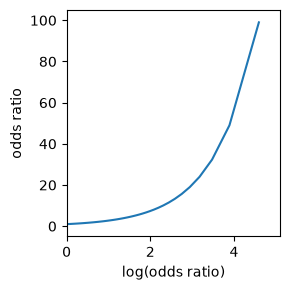

In [46]:
fig, ax = plt.subplots(figsize=(3, 3))
ax.plot(df['logit'], df['odds'])
ax.set_xlabel('log(odds ratio)')
ax.set_ylabel('odds ratio')
ax.set_xlim(0, 5.1)
ax.set_ylim(-5, 105)

plt.tight_layout()
plt.show()

The odds ratio grows exponentially as the log odds ratio increases, which is why small changes in a coefficient can correspond to large changes in the odds.

### 3.5 Assessing the Model

Logistic regression is a special case of a **generalized linear model (GLM)**, which has two components:
- A **probability distribution** (family) for the outcome: binomial for logistic regression.
- A **link function** that connects the response to the predictors: the logit.

Unlike linear regression, there is no closed-form solution. The model is fitted using **maximum likelihood estimation (MLE)**, which finds the coefficients that make the observed data most likely. Model fit is assessed with **deviance**, and models can be compared with AIC.

The statsmodels GLM below requires the outcome to be mapped to numbers (1 for default, 0 for paid off), and reports standard errors, z-values, and p-values for each coefficient.

In [47]:
# use GLM (general linear model) with the binomial family to
# fit a logistic regression
y_numbers = [1 if yi == 'default' else 0 for yi in y]
logit_reg_sm = sm.GLM(y_numbers, X.assign(const=1),
                      family=sm.families.Binomial())
logit_result = logit_reg_sm.fit()
print(logit_result.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                45342
Model:                            GLM   Df Residuals:                    45330
Model Family:                Binomial   Df Model:                           11
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -28757.
Date:                Sat, 17 Oct 2026   Deviance:                       57515.
Time:                        07:54:23   Pearson chi2:                 4.54e+04
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1112
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
payment_inc_ratio      0.0797      0

The coefficients match the encoded scikit-learn model, since both model the probability of default. Most predictors are highly significant; `OWN` (home ownership) is the main exception, with a p-value well above 0.05.

### 3.6 Logistic Regression with Splines

Like linear regression, logistic regression can be extended with splines to capture nonlinear relationships. Below, splines are used for `payment_inc_ratio` and `borrower_score`.

In [48]:
loan_data['is_default'] = (loan_data['outcome'] == 'default').astype(int)

formula = ('is_default ~ bs(payment_inc_ratio, df=8) + purpose_ + ' +
           'home_ + emp_len_ + bs(borrower_score, df=3)')
model = smf.glm(formula=formula, data=loan_data, family=sm.families.Binomial())
results = model.fit()
print(results.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:             is_default   No. Observations:                45342
Model:                            GLM   Df Residuals:                    45321
Model Family:                Binomial   Df Model:                           20
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -28731.
Date:                Sat, 17 Oct 2026   Deviance:                       57462.
Time:                        07:54:24   Pearson chi2:                 4.54e+04
No. Iterations:                     6   Pseudo R-squ. (CS):             0.1122
Covariance Type:            nonrobust                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

The spline terms allow the effect of `payment_inc_ratio` and `borrower_score` on the log odds to bend. A **partial residual plot** shows the shape of this effect for a single predictor, after accounting for the others.

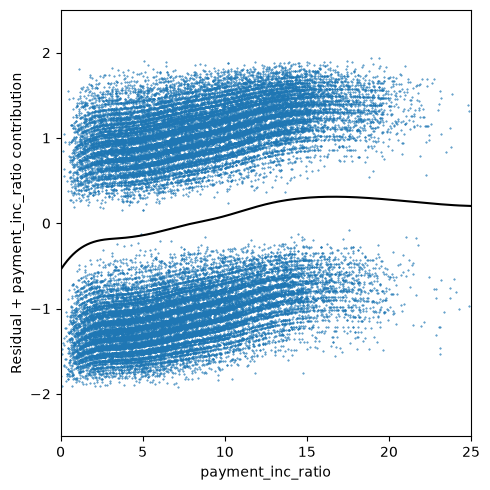

In [49]:
def partialResidualPlot(model, df, outcome, feature, fig, ax):
    y_actual = [0 if s == 'default' else 1 for s in df[outcome]]
    y_pred = model.predict(df)
    org_params = model.params.copy()
    zero_params = model.params.copy()
    # set model parameters of other features to 0
    for i, name in enumerate(zero_params.index):
        if feature in name:
            continue
        zero_params.iloc[i] = 0.0
    model.initialize(model.model, zero_params)
    feature_prediction = model.predict(df)
    ypartial = -np.log(1 / feature_prediction - 1)
    ypartial = ypartial - np.mean(ypartial)
    model.initialize(model.model, org_params)
    results = pd.DataFrame({
        'feature': df[feature],
        'residual': -2 * (y_actual - y_pred),
        'ypartial': ypartial / 2,
    })
    results = results.sort_values(by=['feature'])

    ax.scatter(results.feature, results.residual, marker='.', s=72. / fig.dpi)
    ax.plot(results.feature, results.ypartial, color='black')
    ax.set_xlabel(feature)
    ax.set_ylabel(f'Residual + {feature} contribution')
    return ax

fig, ax = plt.subplots(figsize=(5, 5))
partialResidualPlot(results, loan_data, 'outcome', 'payment_inc_ratio', fig, ax)
ax.set_xlim(0, 25)
ax.set_ylim(-2.5, 2.5)

plt.tight_layout()
plt.show()

The black line shows the estimated effect of `payment_inc_ratio` on the log odds of default. The effect increases with the payment-to-income ratio, but not in a perfectly straight line, which is what the spline captures. The residuals form two bands because the outcome is binary.

## 4. Evaluating Classification Models

The simplest metric is **accuracy**: the percentage of records classified correctly. But accuracy alone can be misleading, especially when one class is rare.

### 4.1 Confusion Matrix

A **confusion matrix** shows the number of correct and incorrect predictions by type:
- **True positive (TP)**: a positive record correctly classified as positive.
- **False negative (FN)**: a positive record wrongly classified as negative.
- **False positive (FP)**: a negative record wrongly classified as positive.
- **True negative (TN)**: a negative record correctly classified as negative.

Here, `default` is treated as the positive class (the class of interest).

In [50]:
# Confusion matrix
pred_y = logit_reg.predict(X) == 'default'
true_y = (y == 'default').to_numpy()
true_pos = true_y & pred_y
true_neg = ~true_y & ~pred_y
false_pos = ~true_y & pred_y
false_neg = true_y & ~pred_y

conf_mat = pd.DataFrame([[np.sum(true_pos), np.sum(false_neg)],
                         [np.sum(false_pos), np.sum(true_neg)]],
                        index=['Y = default', 'Y = paid off'],
                        columns=['Yhat = default', 'Yhat = paid off'])
print(conf_mat)

              Yhat = default  Yhat = paid off
Y = default            14336             8335
Y = paid off            8148            14523


In [51]:
print(confusion_matrix(y, logit_reg.predict(X)))

[[14336  8335]
 [ 8148 14523]]


The package dmba contains the function `classificationSummary`, which prints the confusion matrix and accuracy of a classification model.

In [52]:
classificationSummary(y, logit_reg.predict(X),
                      class_names=logit_reg.classes_)

Confusion Matrix (Accuracy 0.6365)

         Prediction
  Actual  default paid off
 default    14336     8335
paid off     8148    14523


All three methods give the same counts. The model has an accuracy of around 0.64, and the errors are fairly evenly split between false positives and false negatives.

### 4.2 The Rare Class Problem

In many applications the class of interest (fraud, default, disease, a purchase) is rare. A model that always predicts the common class can achieve high accuracy while being useless. In such cases, correctly identifying the rare class is usually more important than overall accuracy.

### 4.3 Precision, Recall, and Specificity

- **Precision**: the proportion of predicted positives that are actually positive. TP / (TP + FP).
- **Recall (sensitivity)**: the proportion of actual positives that are correctly identified. TP / (TP + FN).
- **Specificity**: the proportion of actual negatives that are correctly identified. TN / (TN + FP).

There is a trade-off: catching more positives (higher recall) usually means more false alarms (lower precision).

The scikit-learn function `precision_recall_fscore_support` returns precision, recall, F1-score, and support (number of records) for each class.

In [53]:
conf_mat = confusion_matrix(y, logit_reg.predict(X))
print('Precision', conf_mat[0, 0] / sum(conf_mat[:, 0]))
print('Recall', conf_mat[0, 0] / sum(conf_mat[0, :]))
print('Specificity', conf_mat[1, 1] / sum(conf_mat[1, :]))

Precision 0.6376089663760897
Recall 0.6323496978518812
Specificity 0.6405981209474659


In [54]:
precision_recall_fscore_support(y, logit_reg.predict(X),
                                labels=['default', 'paid off'])

(array([0.63760897, 0.63535742]),
 array([0.6323497 , 0.64059812]),
 array([0.63496844, 0.63796701]),
 array([22671, 22671]))

Precision, recall, and specificity are all around 0.63 to 0.64, which means the model performs similarly for both classes.

### 4.4 ROC Curve

The **ROC (receiver operating characteristics) curve** shows the trade-off between recall and specificity as the classification cutoff changes. The x-axis shows specificity (from 1 to 0) and the y-axis shows recall. A model no better than random guessing follows the diagonal line; the closer the curve is to the upper-left corner, the better. The function `roc_curve` in scikit-learn calculates all the information required to plot it.

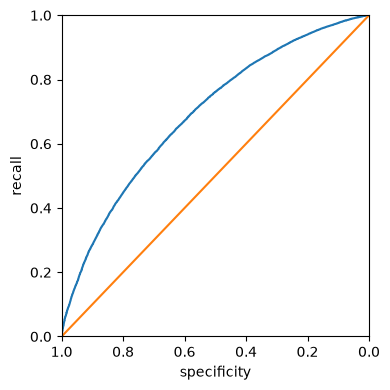

In [55]:
fpr, tpr, thresholds = roc_curve(y, logit_reg.predict_proba(X)[:, 0],
                                 pos_label='default')
roc_df = pd.DataFrame({'recall': tpr, 'specificity': 1 - fpr})

ax = roc_df.plot(x='specificity', y='recall', figsize=(4, 4), legend=False)
ax.set_ylim(0, 1)
ax.set_xlim(1, 0)
ax.plot((1, 0), (0, 1))
ax.set_xlabel('specificity')
ax.set_ylabel('recall')

plt.tight_layout()
plt.show()

### 4.5 AUC

The **AUC (area under the ROC curve)** summarizes the ROC curve in one number. An AUC of 1 means a perfect classifier, while 0.5 means the model is no better than random guessing. Below, AUC is computed manually from the curve and with scikit-learn's `roc_auc_score`.

In [56]:
print(np.sum(roc_df.recall[:-1] * np.diff(1 - roc_df.specificity)))
print(roc_auc_score([1 if yi == 'default' else 0 for yi in y],
                    logit_reg.predict_proba(X)[:, 0]))

0.691710795288669
0.6917108731135808


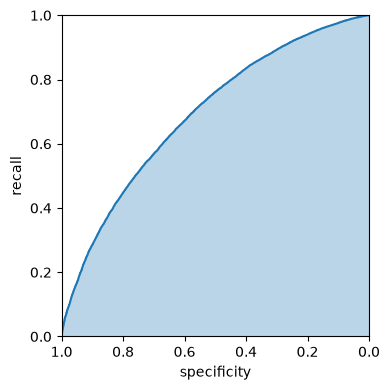

In [57]:
fpr, tpr, thresholds = roc_curve(y, logit_reg.predict_proba(X)[:, 0],
                                 pos_label='default')
roc_df = pd.DataFrame({'recall': tpr, 'specificity': 1 - fpr})

ax = roc_df.plot(x='specificity', y='recall', figsize=(4, 4), legend=False)
ax.set_ylim(0, 1)
ax.set_xlim(1, 0)
ax.set_xlabel('specificity')
ax.set_ylabel('recall')
ax.fill_between(roc_df.specificity, 0, roc_df.recall, alpha=0.3)

plt.tight_layout()
plt.show()

Both calculations give an AUC of around 0.69. The shaded area represents the AUC: the model is clearly better than random guessing, but far from perfect.

### 4.6 Lift

**Lift** measures how effective a model is at identifying the rare class compared to selecting records at random. For example, if the top 10% of records ranked by the model contain three times as many positives as average, the lift for that decile is 3. A **lift curve** (cumulative gains chart) helps decide which cutoff to use in practice, for example how many customers to contact in a campaign.

## 5. Strategies for Imbalanced Data

When one class is much rarer than the other, models tend to predict the common class almost all the time. Several strategies help the model pay more attention to the rare class.

### 5.1 Undersampling

**Undersampling** (downsampling) uses fewer records from the common class so the classes become more balanced. This is reasonable when there is a lot of data, but it throws away information.

The `loan_data` used above is already a balanced (undersampled) dataset. The full training set below is much more imbalanced.

In [58]:
full_train_set = pd.read_csv(FULL_TRAIN_SET_CSV)
print(full_train_set.shape)

(119987, 19)


In [59]:
print('percentage of loans in default:',
      100 * np.mean(full_train_set.outcome == 'default'))

percentage of loans in default: 18.894546909248504


In [60]:
predictors = ['payment_inc_ratio', 'purpose_', 'home_', 'emp_len_',
              'dti', 'revol_bal', 'revol_util']
outcome = 'outcome'
X = pd.get_dummies(full_train_set[predictors], prefix='', prefix_sep='',
                   drop_first=True, dtype=int)
y = full_train_set[outcome]

full_model = LogisticRegression(C=1e42, solver='liblinear')
full_model.fit(X, y)
print('percentage of loans predicted to default:',
      100 * np.mean(full_model.predict(X) == 'default'))

percentage of loans predicted to default: 0.0


In [61]:
(np.mean(full_train_set.outcome == 'default') /
 np.mean(full_model.predict(X) == 'default'))

C:\Users\PRICILIA APRIANA\AppData\Local\Temp\ipykernel_22376\2603836988.py:1: RuntimeWarning: divide by zero encountered in scalar divide
  (np.mean(full_train_set.outcome == 'default') /


np.float64(inf)

About 19% of loans in the full training set are in default, but the model predicts default for only a tiny fraction of loans. The ratio above shows that defaults are underpredicted by a very large factor. This is the rare class problem in action: the model almost always predicts the common class.

### 5.2 Oversampling and Up/Down Weighting

**Oversampling** (upsampling) uses more records from the rare class, typically by sampling with replacement. An alternative with the same effect is **weighting**: giving each rare class record a higher weight. Below, defaults are given a weight equal to 1 divided by their proportion in the data.

In [62]:
default_wt = 1 / np.mean(full_train_set.outcome == 'default')
wt = [default_wt if o == 'default' else 1 for o in full_train_set.outcome]

full_model = LogisticRegression(C=1e42, solver='liblinear')
full_model.fit(X, y, sample_weight=wt)
print('percentage of loans predicted to default (weighting):',
      100 * np.mean(full_model.predict(X) == 'default'))

percentage of loans predicted to default (weighting): 61.43998933217766


With weighting, the model predicts default for around 60% of loans. It now identifies many more of the actual defaults, at the cost of more false positives.

### 5.3 Data Generation

Instead of duplicating rare class records, **data generation** creates new synthetic records that are slightly different from the existing ones. The package imbalanced-learn provides implementations of these algorithms:
- **SMOTE (Synthetic Minority Oversampling Technique)**: for each rare class record, it finds a similar record (using K-nearest neighbors) and creates a synthetic record at a random point between them.
- **ADASYN**: a variant that generates more synthetic records in regions where the rare class is harder to learn.

In [63]:
X_resampled, y_resampled = SMOTE().fit_resample(X, y)
print('percentage of loans in default (SMOTE resampled):',
      100 * np.mean(y_resampled == 'default'))

full_model = LogisticRegression(C=1e42, solver='liblinear')
full_model.fit(X_resampled, y_resampled)
print('percentage of loans predicted to default (SMOTE):',
      100 * np.mean(full_model.predict(X) == 'default'))

X_resampled, y_resampled = ADASYN().fit_resample(X, y)
print('percentage of loans in default (ADASYN resampled):',
      100 * np.mean(y_resampled == 'default'))

full_model = LogisticRegression(C=1e42, solver='liblinear')
full_model.fit(X_resampled, y_resampled)
print('percentage of loans predicted to default (ADASYN):',
      100 * np.mean(full_model.predict(X) == 'default'))

percentage of loans in default (SMOTE resampled): 50.0
percentage of loans predicted to default (SMOTE): 29.40235192145816
percentage of loans in default (ADASYN resampled): 48.56040383751355
percentage of loans predicted to default (ADASYN): 27.21711518747864


After resampling, the training data is (nearly) balanced, and the model predicts default for a much larger share of loans than the original model. The exact percentages vary slightly between runs because SMOTE and ADASYN generate random synthetic records.

### 5.4 Cost-Based Classification

In practice, accuracy or AUC are not always the right criteria. A better approach is to weigh the **costs and benefits** of each outcome. For example, the expected return of a loan can be estimated as P(paid off) × interest earned - P(default) × loss, and the decision can be based on whether this expected return is positive instead of using a fixed probability cutoff.

## 6. Exploring the Predictions

Different models can have similar accuracy but produce very different decision boundaries. With only two predictors, the boundaries can be visualized directly. Below, four models are trained on the `loan3000` data using `borrower_score` and `payment_inc_ratio`:
- a decision tree,
- linear discriminant analysis,
- logistic regression,
- a generalized additive model (GAM).

In [64]:
loan3000 = pd.read_csv(LOAN3000_CSV)

predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_tree = DecisionTreeClassifier(random_state=1, criterion='entropy',
                                   min_impurity_decrease=0.003)
loan_tree.fit(X, y)

loan_lda = LinearDiscriminantAnalysis()
loan_lda.fit(X, y)

logit_reg = LogisticRegression(solver='liblinear')
logit_reg.fit(X, y)

## model
gam = LinearGAM(s(0) + s(1))
print(gam.gridsearch(X.values, [1 if yi == 'default' else 0 for yi in y],
                     progress=False))

LinearGAM(callbacks=[Deviance(), Diffs()], fit_intercept=True, 
   max_iter=100, scale=None, terms=s(0) + s(1) + intercept, 
   tol=0.0001, verbose=False)


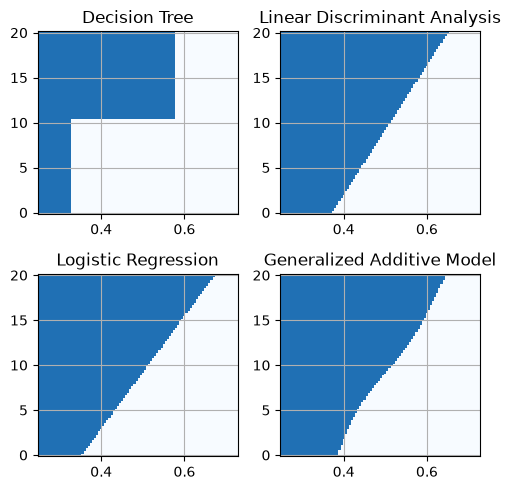

In [65]:
models = {
    'Decision Tree': loan_tree,
    'Linear Discriminant Analysis': loan_lda,
    'Logistic Regression': logit_reg,
    'Generalized Additive Model': gam,
}

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(5, 5))

xvalues = np.arange(0.25, 0.73, 0.005)
yvalues = np.arange(-0.1, 20.1, 0.1)
xx, yy = np.meshgrid(xvalues, yvalues)
X = pd.DataFrame({
    'borrower_score': xx.ravel(),
    'payment_inc_ratio': yy.ravel(),
})

boundary = {}

for n, (title, model) in enumerate(models.items()):
    ax = axes[n // 2, n % 2]
    predict = model.predict(X)
    if 'Generalized' in title:
        Z = np.array([1 if z > 0.5 else 0 for z in predict])
    else:
        Z = np.array([1 if z == 'default' else 0 for z in predict])
    Z = Z.reshape(xx.shape)
    boundary[title] = yvalues[np.argmax(Z > 0, axis=0)]
    boundary[title][Z[-1, :] == 0] = yvalues[-1]

    ax.pcolormesh(xx, yy, Z, cmap='Blues', vmin=0.1, vmax=1.3, shading='auto')
    ax.set_title(title)
    ax.grid(True)

plt.tight_layout()
plt.show()

Each panel shows the region where the model predicts default (dark) versus paid off (light). The decision tree produces a step-shaped boundary, LDA and logistic regression produce straight lines, and the GAM produces a smooth curve.

The plot below overlays the four decision boundaries.

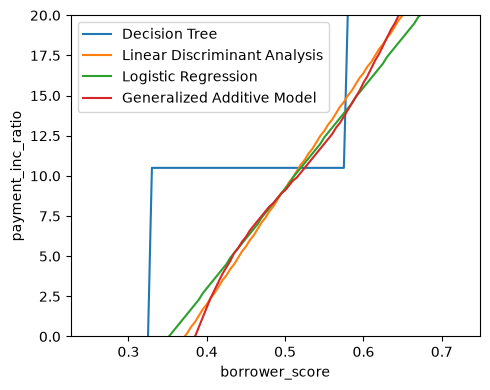

In [66]:
boundary['borrower_score'] = xvalues
boundaries = pd.DataFrame(boundary)

fig, ax = plt.subplots(figsize=(5, 4))
boundaries.plot(x='borrower_score', ax=ax)
ax.set_ylabel('payment_inc_ratio')
ax.set_ylim(0, 20)

plt.tight_layout()
plt.show()

LDA and logistic regression give nearly identical linear boundaries. The GAM boundary is close to them in the middle but curves at the extremes, and the decision tree boundary is a series of steps. Where the boundaries disagree, the models will classify the same loans differently, which shows why exploring predictions is useful in addition to comparing accuracy.

## Summary

This chapter introduces classification: predicting the category of a record, typically a binary outcome.

Key takeaways:
- Naive Bayes estimates class probabilities from categorical predictors by assuming the predictors are conditionally independent. It is simple and often ranks records well, even though its probabilities are biased.
- Linear discriminant analysis finds a linear combination of predictors that best separates the classes.
- Logistic regression models the log odds of the outcome as a linear function of the predictors. Its coefficients can be interpreted as odds ratios, and it is a special case of the generalized linear model fitted by maximum likelihood. Splines can be added to capture nonlinear effects.
- Classification models should be evaluated with the confusion matrix, precision, recall, specificity, ROC curves, AUC, and lift, not only accuracy.
- With imbalanced data, the rare class tends to be heavily underpredicted. Undersampling, oversampling, weighting, synthetic data generation (SMOTE, ADASYN), and cost-based decisions help address this.
- Different classifiers can produce very different decision boundaries even with similar accuracy, so visualizing predictions is a useful diagnostic.